<b>Moving beyond building applications that simply respond to prompts and starting to build AI systems that can think, make decisions, use external tools, and execute tasks.

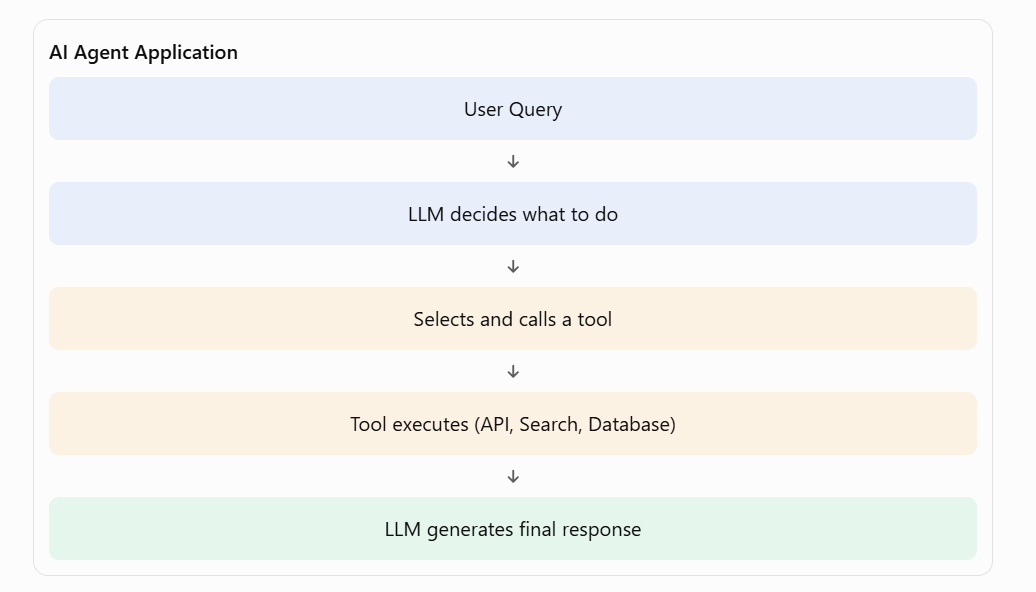

# Table of Contents

1. **Runnables**
2. Tools
3. Agents
4. Project

---

# 1. Runnables



<div style="background:linear-gradient(135deg,#EDE9FE,#DBEAFE); padding:18px; border-left:6px solid #7C3AED; border-radius:10px;">

<h2 style="color:#5B21B6; margin:0;">What are Runnables?</h2>

<strong>Runnables</strong> are the fundamental building blocks of LangChain that allow us to execute individual components and connect them together to create workflows.

</div>

## Why do we need Runnables?

In a typical LLM application, we may need to:

1. Pass input to a prompt.
2. Send the prompt to an LLM.
3. Process the LLM's response.
4. Return the final output.

Runnables provide a standardized way to execute and connect these components.

## Basic Workflow

User Input → Prompt → LLM → Output Parser → Final Output

## Important Runnable Methods

| Method | Purpose |
|---|---|
| `invoke()` | Executes a Runnable with a single input. |
| `batch()` | Executes a Runnable with multiple inputs. |
| `stream()` | Returns output progressively as it is generated. |
| `ainvoke()` | Asynchronously executes a Runnable. |
| `abatch()` | Asynchronously processes multiple inputs. |
| `astream()` | Asynchronously streams output. |

## Simple Example

```python
from langchain_core.runnables import RunnableLambda

def greet(name):
    return f"Hello, {name}!"

runnable = RunnableLambda(greet)

result = runnable.invoke("Rohit")

print(result)

## Actual Runnables

These are your components/runnables:

- LLM
- Prompt Template
- Output Parser
- Retriever
- Tools

> Basically: *They do the actual job.*

## Simple Sequence Runnables (RunnableSequence)

**Simple Sequence Runnables** allow us to connect multiple Runnables together in a specific order, where the output of one Runnable becomes the input of the next Runnable.

In simple words:

> It executes multiple components sequentially, one after another.

### Example Workflow

User Input → Prompt Template → LLM → Output Parser → Final Output

### How It Works

1. **Prompt Template:** Takes user input and creates a formatted prompt.
2. **LLM:** Receives the prompt and generates a response.
3. **Output Parser:** Processes the LLM response into the required format.
4. **Final Output:** Returns the processed result.

### Python Example

```python
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_groq import ChatGroq

prompt = ChatPromptTemplate.from_template(
    "Tell me a short joke about {topic}"
)

llm = ChatGroq(
    model="openai/gpt-oss-20b"
)

parser = StrOutputParser()

# Connecting Runnables using the pipe operator
chain = prompt | llm | parser

result = chain.invoke({"topic": "Python"})

print(result)

2. Parallel Runnables in LangChain allow you to execute multiple Runnables simultaneously using the same input and collect their outputs together.

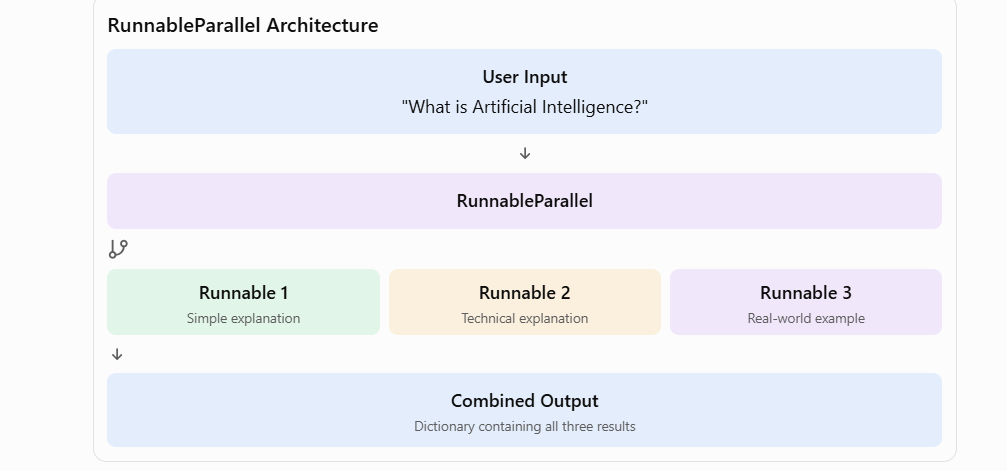

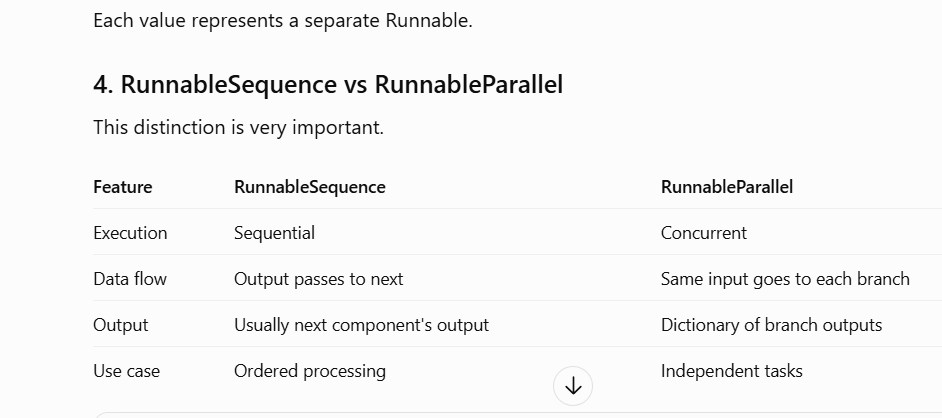